## 2230-0035 Jawad Hassan
## Word 2  Vec
## Assignment 2

In [2]:
import re, glob, collections
import nltk
from nltk.tokenize import sent_tokenize
import gensim
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

nltk.download('punkt_tab')          # fresh venv has no nltk data yet
print("gensim", gensim.__version__)

gensim 4.4.0


[nltk_data] Downloading package punkt_tab to C:\Users\Jawad
[nltk_data]     Hassan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [3]:
# read the 5 got books, handle mixed encodings, strip page numbers, merge into one corpus

PAGE = re.compile(r"(?mi)^\s*page\s+\d+\s*$")

def read_book(path):
    for enc in ("utf-8", "cp1252"):          # books 4 and 5 are cp1252
        try:
            with open(path, encoding=enc) as f:
                return f.read(), enc
        except UnicodeDecodeError:
            continue
    raise ValueError(f"could not decode {path}")

texts = []
for path in sorted(glob.glob("*.txt")):
    text, enc = read_book(path)
    text = PAGE.sub(" ", text)                                   # drop "Page 571"
    lines = (ln.strip() for ln in text.splitlines())
    text = " ".join(ln for ln in lines if ln)                    # undo the hard wrapping
    texts.append(text)
    print(f"{path[:30]:32s} {enc:6s} {len(text.split()):>7,} words")

corpus_text = " ".join(texts)
print("\ncombined:", f"{len(corpus_text.split()):,}", "words")

1 - A Game of Thrones.txt        utf-8  295,041 words
2 - A Clash of Kings.txt         utf-8  326,421 words
3 - A Storm of Swords.txt        utf-8  424,919 words
4 - A Feast for Crows.txt        cp1252 313,420 words
5 - A Dance with Dragons.txt     cp1252 426,259 words

combined: 1,786,060 words


In [4]:
# split the corpus into sentences and tokenize each one for word2vec

sentences = sent_tokenize(corpus_text)
print(f"{len(sentences):,} sentences")

tokens = [simple_preprocess(s) for s in sentences]
tokens = [t for t in tokens if len(t) > 1]      # drop one-word fragments

print(f"{len(tokens):,} usable sentences")
print(f"{sum(len(t) for t in tokens):,} tokens")
print(tokens[0][:14])

158,790 sentences
150,797 usable sentences
1,719,688 tokens
['game', 'of', 'thrones', 'book', 'one', 'of', 'song', 'of', 'ice', 'and', 'fire', 'by', 'george', 'martin']


In [5]:
# build vocabulary and train both word2vec variants: skip-gram and cbow

import time

def train_model(sg, label):
    t0 = time.time()
    m = Word2Vec(vector_size=100, window=5, min_count=5,
                 sg=sg, workers=4, seed=42)
    m.build_vocab(tokens)
    m.train(tokens, total_examples=m.corpus_count, epochs=10)
    print(f"{label:10s} vocab {len(m.wv):,}  trained in {time.time() - t0:.1f}s")
    m.save(f"got_{label}.model")
    return m

sg_model   = train_model(1, "skip-gram")   # predicts context from target
cbow_model = train_model(0, "cbow")        # predicts target from context

skip-gram  vocab 11,743  trained in 10.9s
cbow       vocab 11,743  trained in 4.0s


In [6]:
# compare nearest neighbours from both models side by side

def compare(word, topn=5):
    print(f"\n=== {word} ===")
    for label, m in (("skip-gram", sg_model), ("cbow", cbow_model)):
        if word in m.wv:
            hits = ", ".join(f"{w} {s:.2f}" for w, s in m.wv.most_similar(word, topn=topn))
            print(f"  {label:10s} {hits}")
        else:
            print(f"  {label:10s} not in vocabulary")

for w in ["jon", "arya", "winterfell", "dragon", "king", "stark"]:
    compare(w)


=== jon ===
  skip-gram  stonesnake 0.70, ion 0.68, sam 0.68, ygritte 0.63, ned 0.63
  cbow       sam 0.66, theon 0.64, bran 0.63, davos 0.59, ion 0.58

=== arya ===
  skip-gram  sansa 0.79, brienne 0.72, she 0.70, catelyn 0.70, gendry 0.64
  cbow       sansa 0.82, she 0.79, brienne 0.78, catelyn 0.73, gendry 0.71

=== winterfell ===
  skip-gram  stark 0.70, eddard 0.67, riverrun 0.66, executed 0.64, robb 0.63
  cbow       riverrun 0.77, harrenhal 0.73, eyrie 0.66, robb 0.61, vale 0.60

=== dragon ===
  skip-gram  dragons 0.67, targaryen 0.62, drogon 0.57, lion 0.56, viserion 0.55
  cbow       dragons 0.51, slaver 0.47, targaryen 0.47, bitch 0.47, lion 0.45

=== king ===
  skip-gram  conciliator 0.67, landing 0.64, baratheon 0.64, ii 0.62, issue 0.61
  cbow       baratheon 0.64, realm 0.59, usurper 0.51, tourney 0.51, ninth 0.48

=== stark ===
  skip-gram  eddard 0.77, winterfell 0.70, executed 0.67, direwolf 0.64, robb 0.63
  cbow       winterfell 0.58, tully 0.52, robb 0.52, arryn 0

## Analysis: nearest neighbours (skip-gram vs CBOW)

**What the score means.** Each word is a 100-dimensional vector, and the number is the cosine
similarity between two of them. It measures how similarly two words are *used*, not how they are
*related* in the story — the model never read the plot, only which words occur in similar contexts.

**What the results show**

- `arya` → `sansa` (0.79 / 0.82) is the strongest pair. Both are POV Stark girls described in the
  same language, so they are interchangeable in a sentence.
- `she` ranks in the top three for `arya` in both models, so the vectors also encode grammatical gender.
- `jon` returns his scene companions (`sam`, `stonesnake`, `ygritte`, `ned`), not his family.
- `winterfell` under CBOW returns other castles (`riverrun`, `harrenhal`, `eyrie`, `vale`),
  while skip-gram returns `stark` and `eddard`.
- `king` returns what grammatically follows the title — place names, regnal numerals and epithets
  (`landing`, `ii`, `ninth`, `conciliator`, `usurper`).
- Both models place `lion` near `dragon`: house-sigil words share the same heraldic contexts.

**Skip-gram vs CBOW.** CBOW consistently returns *substitutable* words (other castles, other
houses) because it averages the context window. Skip-gram additionally surfaces rare co-occurring
names: `conciliator` occurs only 6 times in 1.79M words and `stonesnake` 47 times, yet skip-gram
ranks them highly. CBOW's top scores run higher (0.82 vs 0.79) because averaging produces a tighter
vector space, so scores are comparable *within* a model but never across the two.

**Limitation.** Cosine similarity cannot distinguish kinship from any other co-occurrence: siblings
(arya–sansa 0.79), lovers (jon–ygritte 0.63), friends (jon–sam 0.68) and unrelated characters
(arya–brienne 0.72) all score alike.

In [7]:
# cosine similarity matrix between the stark family members

import numpy as np
import pandas as pd

starks = ["ned", "catelyn", "robb", "sansa", "arya", "bran", "rickon", "jon"]

def sim_matrix(model, words):
    words = [w for w in words if w in model.wv]
    return pd.DataFrame([[model.wv.similarity(a, b) for b in words] for a in words],
                        index=words, columns=words)

print(sim_matrix(sg_model, starks).round(2))

          ned  catelyn  robb  sansa  arya  bran  rickon   jon
ned      1.00     0.65  0.64   0.70  0.60  0.62    0.42  0.63
catelyn  0.65     1.00  0.65   0.73  0.70  0.59    0.41  0.52
robb     0.64     0.65  1.00   0.55  0.52  0.61    0.61  0.44
sansa    0.70     0.73  0.55   1.00  0.79  0.65    0.51  0.45
arya     0.60     0.70  0.52   0.79  1.00  0.64    0.46  0.48
bran     0.62     0.59  0.61   0.65  0.64  1.00    0.74  0.58
rickon   0.42     0.41  0.61   0.51  0.46  0.74    1.00  0.35
jon      0.63     0.52  0.44   0.45  0.48  0.58    0.35  1.00


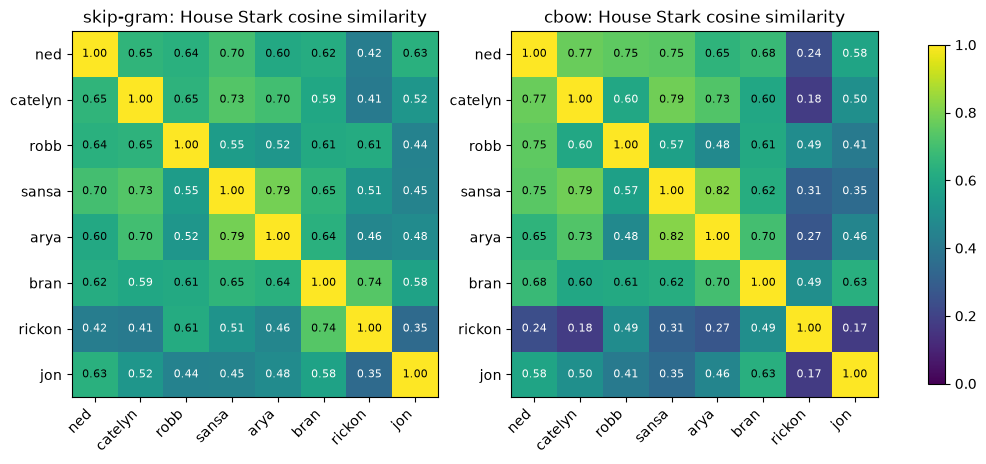

In [8]:
# heatmap of the stark similarity matrix, skip-gram vs cbow

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, (label, model) in zip(axes, (("skip-gram", sg_model), ("cbow", cbow_model))):
    d = sim_matrix(model, starks)
    im = ax.imshow(d.values, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(d))); ax.set_xticklabels(d.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
    for i in range(len(d)):
        for j in range(len(d)):
            v = d.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v < 0.6 else "black", fontsize=8)
    ax.set_title(f"{label}: House Stark cosine similarity")

fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

In [9]:
# quantitative test: are stark-stark pairs closer than stark-lannister pairs?

lannisters = ["tywin", "cersei", "jaime", "tyrion"]
siblings   = ["robb", "sansa", "arya", "bran", "jon"]

for label, model in (("skip-gram", sg_model), ("cbow", cbow_model)):
    within = np.mean([model.wv.similarity(x, y)
                      for i, x in enumerate(siblings) for y in siblings[i+1:]])
    cross  = np.mean([model.wv.similarity(x, y)
                      for x in siblings for y in lannisters])
    print(f"{label:10s} within-Stark {within:.3f}   Stark-vs-Lannister {cross:.3f}   gap {within-cross:+.3f}")

skip-gram  within-Stark 0.572   Stark-vs-Lannister 0.415   gap +0.157
cbow       within-Stark 0.564   Stark-vs-Lannister 0.366   gap +0.199


skip-gram  PC1 18.9%  PC2 12.5%  total 31.4%
cbow       PC1 23.7%  PC2 17.3%  total 41.0%


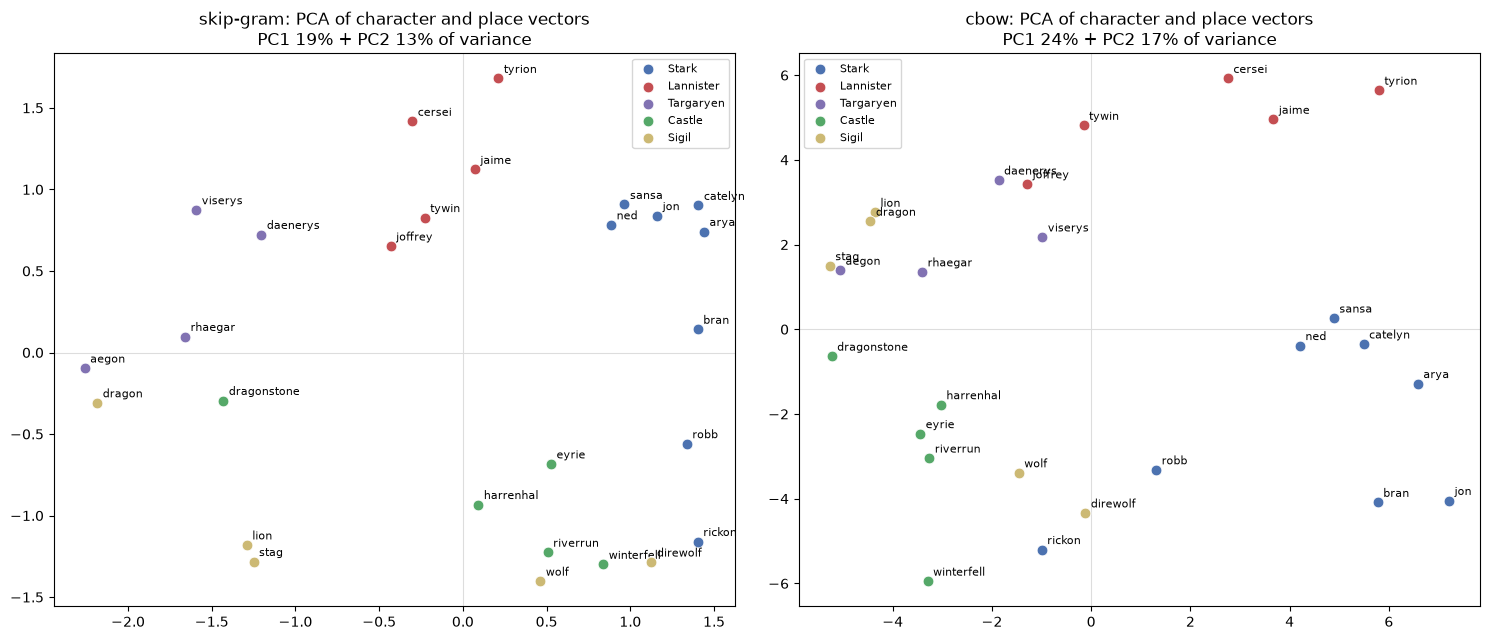

In [10]:
# reduce the 100-dim vectors to 2d with pca and plot characters, castles and sigils by group

from sklearn.decomposition import PCA

groups = {
    "Stark":     ["ned", "catelyn", "robb", "sansa", "arya", "bran", "rickon", "jon"],
    "Lannister": ["tywin", "cersei", "jaime", "tyrion", "joffrey"],
    "Targaryen": ["daenerys", "viserys", "rhaegar", "aegon"],
    "Castle":    ["winterfell", "riverrun", "harrenhal", "eyrie", "dragonstone"],
    "Sigil":     ["wolf", "lion", "dragon", "stag", "direwolf"],
}

COLORS = {"Stark": "#4C72B0", "Lannister": "#C44E52", "Targaryen": "#8172B2",
          "Castle": "#55A868", "Sigil": "#CCB974"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for ax, (label, model) in zip(axes, (("skip-gram", sg_model), ("cbow", cbow_model))):
    words = [(w, g) for g, ws in groups.items() for w in ws if w in model.wv]
    X = np.array([model.wv[w] for w, _ in words])

    pca = PCA(n_components=2, random_state=0)
    xy = pca.fit_transform(X)
    ev = pca.explained_variance_ratio_
    print(f"{label:10s} PC1 {ev[0]:.1%}  PC2 {ev[1]:.1%}  total {ev.sum():.1%}")

    seen = set()
    for (w, g), (x, y) in zip(words, xy):
        ax.scatter(x, y, c=COLORS[g], s=60, label=g if g not in seen else None,
                   edgecolors="white", linewidths=0.6, zorder=3)
        seen.add(g)
        ax.annotate(w, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")

    ax.set_title(f"{label}: PCA of character and place vectors\n"
                 f"PC1 {ev[0]:.0%} + PC2 {ev[1]:.0%} of variance")
    ax.axhline(0, color="#ddd", lw=0.8, zorder=1)
    ax.axvline(0, color="#ddd", lw=0.8, zorder=1)
    ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## Analysis: PCA projection of the vectors

The 100 dimensions are compressed to 2 so the vectors can be plotted. Note that the two
components retain only **31.4%** of the variance for skip-gram (**41.0%** for CBOW), so the
picture understates how well-separated the words really are — points that look close in 2D are
not necessarily close in 100D.

**What the plot shows**

- **The houses form distinct clusters.** Starks, Lannisters and Targaryens each occupy their own
  region in both models, even though the model was never told that houses exist. It inferred them
  purely from which names share contexts.
- **Skip-gram's PC2 largely separates places from people.** Every castle (`harrenhal`,
  `riverrun`, `eyrie`, `winterfell`, `dragonstone`) and every sigil word falls in the lower half
  of the plot with most characters above them; only `robb` and `rickon` cross into that region.
- **`rickon` sits beside `robb`** in skip-gram despite appearing only 195 times, while CBOW pushes
  him to the edge of the Stark group — the rare-word difference again.
- **CBOW separates the groups more widely** (41.0% vs 31.4% of variance in 2D), consistent with
  its smoother, tighter vector space.
- **The sigil words spread across the plot** rather than clustering, because `wolf`, `lion` and
  `dragon` appear both as heraldry and as literal animals, giving them mixed contexts.

**Caveat.** PCA is a linear projection and picks the directions of greatest variance, which are
not necessarily the most meaningful ones. t-SNE or UMAP would show local neighbourhoods better,
at the cost of making global distances meaningless.

In [11]:
# show the vectors themselves: matrix size, one raw vector, and a readable slice

print("skip-gram vector matrix:", sg_model.wv.vectors.shape,
      f"= {sg_model.wv.vectors.size:,} numbers")
print("cbow vector matrix     :", cbow_model.wv.vectors.shape)

v = sg_model.wv["jon"]
print(f"\nraw vector for 'jon' (first 20 of {len(v)} dimensions):")
print(np.round(v[:20], 3))
print(f"\nmin {v.min():.3f}   max {v.max():.3f}   mean {v.mean():.3f}   L2 norm {np.linalg.norm(v):.3f}")

chars = ["jon", "arya", "sansa", "tyrion", "daenerys", "winterfell"]
table = pd.DataFrame([sg_model.wv[w][:8] for w in chars], index=chars,
                     columns=[f"d{i}" for i in range(8)]).round(3)
print("\nfirst 8 dimensions for a few words:")
print(table)

print("\nmost and least frequent words in the vocabulary:")
words = sg_model.wv.index_to_key
print("  top 10 :", words[:10])
print("  last 10:", words[-10:])

skip-gram vector matrix: (11743, 100) = 1,174,300 numbers
cbow vector matrix     : (11743, 100)

raw vector for 'jon' (first 20 of 100 dimensions):
[ 0.535  0.001  0.516  0.22  -0.203  0.18   0.349  0.515 -0.512  0.152
 -0.16   0.177 -0.103  0.651 -0.421  0.024  0.233 -0.355  0.314 -0.506]

min -0.600   max 0.963   mean 0.030   L2 norm 3.393

first 8 dimensions for a few words:
               d0     d1     d2     d3     d4     d5     d6     d7
jon         0.535  0.001  0.516  0.220 -0.203  0.180  0.349  0.515
arya        0.543  0.077  0.446  0.336  0.160  0.269  0.537 -0.113
sansa       0.441  0.001  0.404  0.277  0.339  0.368  0.430 -0.032
tyrion      0.589 -0.296  0.083  0.262  0.097  0.527  0.528  0.068
daenerys    0.486  0.394 -0.171  0.178  0.053  0.718  0.277  0.019
winterfell  0.639  0.280  0.505  0.279 -0.276 -0.100  0.354 -0.044

most and least frequent words in the vocabulary:
  top 10 : ['the', 'and', 'to', 'of', 'he', 'his', 'was', 'you', 'her', 'in']
  last 10: ['starvatio

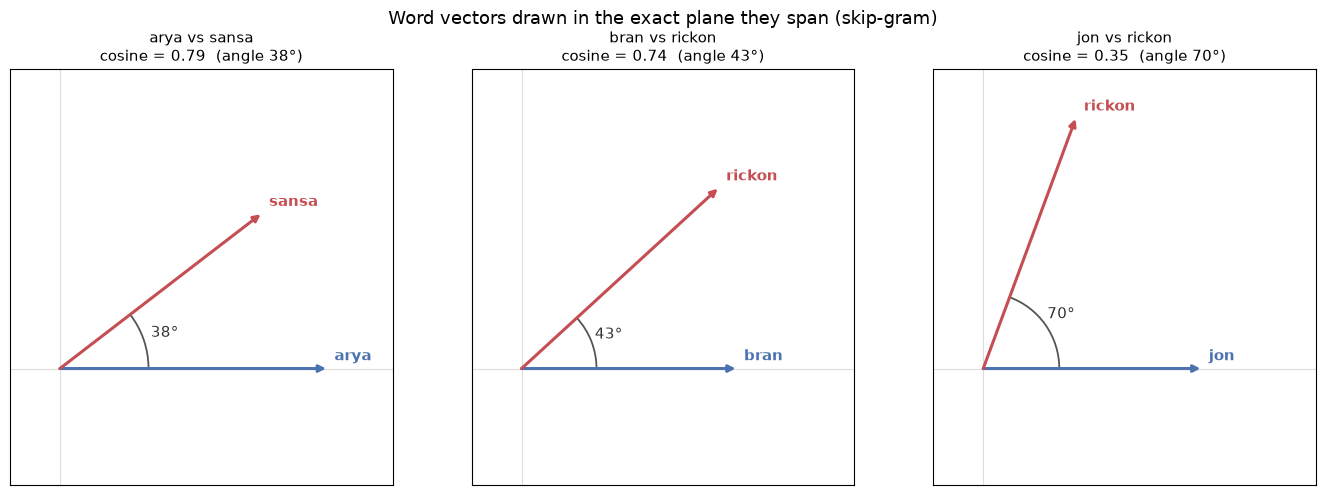

In [12]:
# draw word pairs as 2d arrows so the cosine similarity is visible as an angle

from matplotlib.patches import Arc

def plane_coords(a, b):
    """2D coords in the plane spanned by a and b: lengths and angle are exact."""
    e1 = a / np.linalg.norm(a)
    perp = b - np.dot(b, e1) * e1
    e2 = perp / np.linalg.norm(perp)
    return (np.array([np.dot(a, e1), np.dot(a, e2)]),
            np.array([np.dot(b, e1), np.dot(b, e2)]))

def plot_pair(ax, model, w1, w2):
    a, b = model.wv[w1], model.wv[w2]
    pa, pb = plane_coords(a, b)
    cos = model.wv.similarity(w1, w2)
    deg = np.degrees(np.arccos(np.clip(cos, -1, 1)))

    for (x, y), w, c in ((pa, w1, "#4C72B0"), (pb, w2, "#C44E52")):
        ax.annotate("", xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", lw=2.2, color=c,
                                    shrinkA=0, shrinkB=0))
        ax.annotate(w, (x, y), color=c, fontsize=11, fontweight="bold",
                    xytext=(6, 6), textcoords="offset points")

    # arc marking the angle between them
    r = min(np.linalg.norm(pa), np.linalg.norm(pb)) * 0.35
    a1 = np.degrees(np.arctan2(pa[1], pa[0]))
    a2 = np.degrees(np.arctan2(pb[1], pb[0]))
    ax.add_patch(Arc((0, 0), 2*r, 2*r, theta1=min(a1, a2), theta2=max(a1, a2),
                     color="#555", lw=1.3))
    mid = np.radians((a1 + a2) / 2)
    ax.text(r*1.25*np.cos(mid), r*1.25*np.sin(mid), f"{deg:.0f}°",
            fontsize=11, color="#333", ha="center", va="center")

    lim = max(np.linalg.norm(pa), np.linalg.norm(pb)) * 1.25
    ax.set_xlim(-0.15*lim, lim); ax.set_ylim(-0.35*lim, lim*0.9)
    ax.set_aspect("equal")
    ax.axhline(0, color="#ddd", lw=0.8, zorder=0)
    ax.axvline(0, color="#ddd", lw=0.8, zorder=0)
    ax.set_title(f"{w1} vs {w2}\ncosine = {cos:.2f}  (angle {deg:.0f}°)", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

pairs = [("arya", "sansa"), ("bran", "rickon"), ("jon", "rickon")]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (w1, w2) in zip(axes, pairs):
    plot_pair(ax, sg_model, w1, w2)
fig.suptitle("Word vectors drawn in the exact plane they span (skip-gram)", fontsize=13)
plt.tight_layout()
plt.show()

## Visualising similarity as an angle

Cosine similarity *is* the angle between two vectors, so the clearest way to see it is to draw
the vectors. Each pair below is plotted in the two-dimensional plane that those two vectors span,
constructed by Gram-Schmidt from the vectors themselves. Unlike a PCA projection this discards
nothing: the arrow lengths are the true vector norms and the angle shown is the true angle in
100 dimensions.

The sisters `arya` and `sansa` sit about 38° apart (cosine 0.79) and the young brothers `bran`
and `rickon` about 43° (cosine 0.74), while `jon` and `rickon` open out to 70° (cosine 0.35) —
the same Jon-as-outlier effect seen in the heatmap, now visible geometrically. Note that a cosine
of 0 would be a right angle, so even the "distant" pair is still well inside 90°: no two character
names in this corpus are truly unrelated, since they all appear in the same kind of narrative text.